In [ ]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

# Configuración de estilo para gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

In [ ]:
# Descarga automática desde Kaggle
raw_path = kagglehub.dataset_download("aarishasifkhan/plantvillage-potato-disease-dataset")
base_path = os.path.join(raw_path, "PlantVillage") if os.path.exists(os.path.join(raw_path, "PlantVillage")) else raw_path

CLASSES = ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
extensiones = ('.jpg', '.jpeg', '.png', '.bmp')

# Carga de imágenes
X_list, y_list = [], []
for label_idx, class_name in enumerate(CLASSES):
    class_path = os.path.join(base_path, class_name)
    files = sorted([f for f in os.listdir(class_path) if f.lower().endswith(extensiones)])
    for f in files:
        img = cv2.imread(os.path.join(class_path, f))
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_resized = cv2.resize(img, (128, 128))
            img_norm = img_resized.astype("float32") / 255.0
            X_list.append(img_norm)
            y_list.append(label_idx)

X = np.array(X_list)
y = np.array(y_list)

print(f"Dataset cargado correctamente: {X.shape[0]} imágenes en total.")
for idx, name in enumerate(CLASSES):
    print(f" - Clase {idx} ({name.split('___')[-1]}): {np.sum(y == idx)} imágenes")

100%|██████████| 37.8M/37.8M [00:00<00:00, 83.9MB/s]

Extracting files...


Dataset cargado correctamente: 2152 imágenes en total.
 - Clase 0 (Early_blight): 1000 imágenes
 - Clase 1 (Late_blight): 1000 imágenes
 - Clase 2 (healthy): 152 imágenes


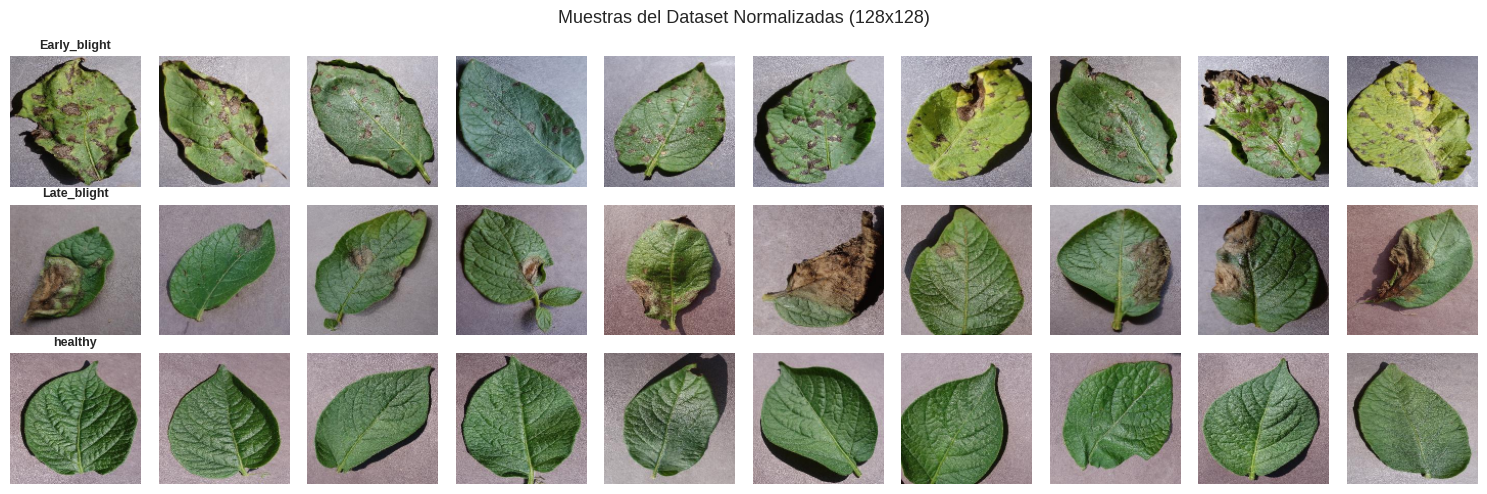

In [ ]:
# Visualización de muestra: 10 imágenes por clase
fig, axes = plt.subplots(3, 10, figsize=(15, 5))
for label_idx, class_name in enumerate(CLASSES):
    indices = np.where(y == label_idx)[0][:10]
    for i, idx in enumerate(indices):
        axes[label_idx, i].imshow(X[idx])
        axes[label_idx, i].axis('off')
        if i == 0:
            axes[label_idx, i].set_title(class_name.split('___')[-1], fontsize=9, fontweight='bold')

plt.suptitle("Muestras del Dataset Normalizadas (128x128)", fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Conjunto de Entrenamiento: {X_train.shape[0]} muestras")
print(f"Conjunto de Validación:    {X_val.shape[0]} muestras")

Conjunto de Entrenamiento: 1506 muestras
Conjunto de Validación:    646 muestras


In [ ]:
def extraer_hog(imagenes):
    hog_features = []
    for img in imagenes:
        img_gray = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        features = hog(img_gray, orientations=9, pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2), block_norm='L2-Hys', visualize=False)
        hog_features.append(features)
    return np.array(hog_features)

def extraer_lbp(imagenes, P=8, R=1):
    lbp_features = []
    for img in imagenes:
        img_gray = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        lbp = local_binary_pattern(img_gray, P=P, R=R, method="uniform")
        (hist, _) = np.histogram(lbp.ravel(), bins=np.arange(0, P + 3), range=(0, P + 2))
        hist = hist.astype("float32")
        hist /= (hist.sum() + 1e-7)
        lbp_features.append(hist)
    return np.array(lbp_features)

def extraer_glcm(imagenes, distances=[1, 3], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4]):
    glcm_features = []
    propiedades = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
    for img in imagenes:
        img_gray = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        img_gray_q = (img_gray // 4).astype(np.uint8)
        glcm = graycomatrix(img_gray_q, distances=distances, angles=angles, levels=64, symmetric=True, normed=True)
        vector_img = []
        for prop in propiedades:
            valores = graycoprops(glcm, prop).ravel()
            vector_img.extend(valores)
        glcm_features.append(vector_img)
    return np.array(glcm_features)

In [ ]:
print("Extrayendo HOG...")
X_tr_hog, X_va_hog = extraer_hog(X_train), extraer_hog(X_val)

print("Extrayendo LBP...")
X_tr_lbp, X_va_lbp = extraer_lbp(X_train), extraer_lbp(X_val)

print("Extrayendo GLCM...")
X_tr_glcm, X_va_glcm = extraer_glcm(X_train), extraer_glcm(X_val)

# Fusión
X_tr_fusion = np.hstack((X_tr_hog, X_tr_lbp, X_tr_glcm))
X_va_fusion = np.hstack((X_va_hog, X_va_lbp, X_va_glcm))

# Normalización Z-score por descriptor
scaler_hog, scaler_lbp, scaler_glcm, scaler_fusion = StandardScaler(), StandardScaler(), StandardScaler(), StandardScaler()

datasets_features = {
    'HOG': (scaler_hog.fit_transform(X_tr_hog), scaler_hog.transform(X_va_hog)),
    'LBP': (scaler_lbp.fit_transform(X_tr_lbp), scaler_lbp.transform(X_va_lbp)),
    'GLCM': (scaler_glcm.fit_transform(X_tr_glcm), scaler_glcm.transform(X_va_glcm)),
    'FUSIÓN (HOG+LBP+GLCM)': (scaler_fusion.fit_transform(X_tr_fusion), scaler_fusion.transform(X_va_fusion))
}

for name, (tr, va) in datasets_features.items():
    print(f"Descriptor {name:<22} -> Dimensiones: {tr.shape[1]}")

Extrayendo HOG...
Extrayendo LBP...
Extrayendo GLCM...
Descriptor HOG                    -> Dimensiones: 8100
Descriptor LBP                    -> Dimensiones: 10
Descriptor GLCM                   -> Dimensiones: 48
Descriptor FUSIÓN (HOG+LBP+GLCM)  -> Dimensiones: 8158


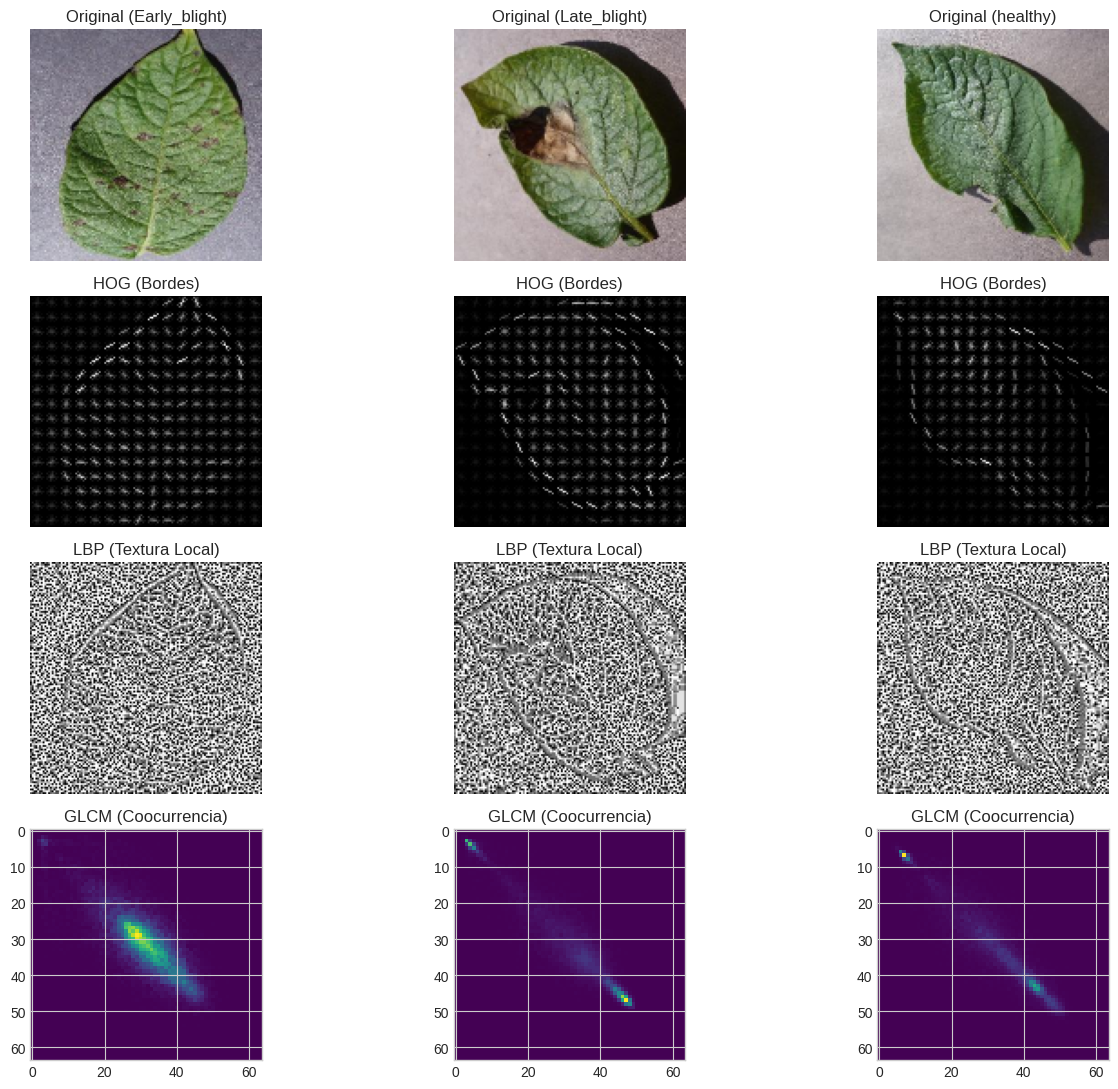

In [ ]:
idxs = [np.where(y_val == i)[0][0] for i in range(3)]

fig, axes = plt.subplots(4, 3, figsize=(14, 11))
for i, idx in enumerate(idxs):
    img_gray = cv2.cvtColor((X_val[idx] * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
    _, hog_vis = hog(img_gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    lbp_vis = local_binary_pattern(img_gray, P=8, R=1, method="uniform")
    img_q = (img_gray // 4).astype(np.uint8)
    glcm_vis = graycomatrix(img_q, distances=[1], angles=[0], levels=64, symmetric=True, normed=True)[:, :, 0, 0]

    title_cls = CLASSES[i].split('___')[-1]

    axes[0, i].imshow(X_val[idx]); axes[0, i].set_title(f"Original ({title_cls})"); axes[0, i].axis('off')
    axes[1, i].imshow(hog_vis, cmap='gray'); axes[1, i].set_title("HOG (Bordes)"); axes[1, i].axis('off')
    axes[2, i].imshow(lbp_vis, cmap='gray'); axes[2, i].set_title("LBP (Textura Local)"); axes[2, i].axis('off')
    axes[3, i].imshow(glcm_vis, cmap='viridis'); axes[3, i].set_title("GLCM (Coocurrencia)")

plt.tight_layout()
plt.show()

In [ ]:
models = {
    'k-NN (k=5)': KNeighborsClassifier(n_neighbors=5, metric='euclidean'),
    'SVM (RBF)': SVC(kernel='rbf', C=1.0, probability=True, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

results = []

for feat_name, (X_tr, X_va) in datasets_features.items():
    for model_name, model in models.items():
        t0 = time.time()
        model.fit(X_tr, y_train)
        y_pred = model.predict(X_va)
        t_exec = time.time() - t0

        results.append({
            'Descriptor': feat_name,
            'Modelo': model_name,
            'Dimensiones': X_tr.shape[1],
            'Accuracy': accuracy_score(y_val, y_pred),
            'Precision': precision_score(y_val, y_pred, average='weighted', zero_division=0),
            'Recall': recall_score(y_val, y_pred, average='weighted', zero_division=0),
            'F1-Score': f1_score(y_val, y_pred, average='weighted', zero_division=0),
            'Tiempo (s)': t_exec
        })

df_results = pd.DataFrame(results)

print("="*85)
print("TABLA CONSOLIDADA DE RESULTADOS (BENCHMARK MULTICLASE HOJAS DE PAPA)")
print("="*85)
print(df_results.to_string(index=False))

TABLA CONSOLIDADA DE RESULTADOS (BENCHMARK MULTICLASE HOJAS DE PAPA)
           Descriptor        Modelo  Dimensiones  Accuracy  Precision   Recall  F1-Score  Tiempo (s)
                  HOG    k-NN (k=5)         8100  0.696594   0.716350 0.696594  0.700045    0.666465
                  HOG     SVM (RBF)         8100  0.773994   0.723160 0.773994  0.746204  119.975464
                  HOG Random Forest         8100  0.739938   0.686981 0.739938  0.712339   16.088468
                  LBP    k-NN (k=5)           10  0.653251   0.651484 0.653251  0.649057    0.018133
                  LBP     SVM (RBF)           10  0.730650   0.730317 0.730650  0.724804    0.482346
                  LBP Random Forest           10  0.719814   0.714535 0.719814  0.712918    0.535044
                 GLCM    k-NN (k=5)           48  0.818885   0.815208 0.818885  0.805993    0.012829
                 GLCM     SVM (RBF)           48  0.840557   0.836823 0.840557  0.822804    0.353380
                 GLCM 

<Figure size 1100x600 with 0 Axes>

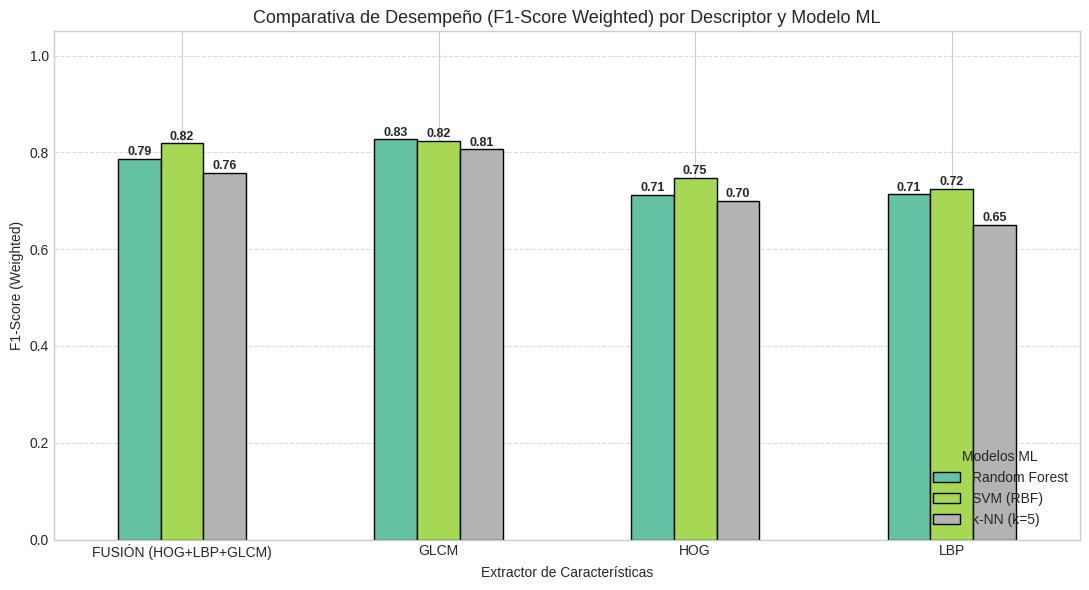

In [ ]:
plt.figure(figsize=(11, 6))
df_pivot = df_results.pivot(index='Descriptor', columns='Modelo', values='F1-Score')

ax = df_pivot.plot(kind='bar', figsize=(11, 6), colormap='Set2', edgecolor='black')
plt.title("Comparativa de Desempeño (F1-Score Weighted) por Descriptor y Modelo ML", fontsize=13)
plt.ylabel("F1-Score (Weighted)")
plt.xlabel("Extractor de Características")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title="Modelos ML", loc='lower right')

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5),
                    textcoords='offset points', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()